In [1]:
import sys
sys.path.append('../scripts')
from utils.cftp_func import *
import glob
from scipy.stats import linregress

In [2]:
julia_colors = [
    '#00A9AD',  # teal
    '#E28F41',  # orange
    '#389826',  # green
    '#9558B2',  # purple
    '#CB3C33',  # red
    '#7C7C7C',  # grey
    '#BB7DC0',  # light purple
    '#4063D8',  # blue
]
from cycler import cycler
plt.rcParams['axes.prop_cycle'] = cycler(color=julia_colors)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['legend.frameon'] = False

plt.rcParams['font.size'] = 14          
plt.rcParams['axes.labelsize'] = 16     
plt.rcParams['xtick.labelsize'] = 13
plt.rcParams['ytick.labelsize'] = 13
plt.rcParams['legend.fontsize'] = 12
plt.rcParams['axes.titlesize'] = 16

In [40]:
graph_type = 'EA3D'
coup_type = 'ising'
d = 3
if graph_type == 'ER' and coup_type == 'ising':
    beta_SG = np.arctanh(np.sqrt(1/d))
    beta_uni = np.arctanh(1/d)
    print(f"beta_uni = {beta_uni:.6f}, beta_SG = {beta_SG:.6f}")
elif graph_type == 'ER' and coup_type == 'gauss':
    beta_uni = solve_beta_critical_gauss(d=4)
    print(f"beta_uni = {beta_uni:.6f}")
elif graph_type == 'RR' and coup_type == 'ising':
    beta_SG = np.arctanh(np.sqrt(1/(d-1)))
    beta_uni = np.arctanh(1/(d-1))
    beta_dob = np.arctanh(1/d)
    print(f"beta_dob = {beta_dob:.6f}, beta_uni = {beta_uni:.6f}, beta_SG = {beta_SG:.6f}")
elif graph_type == 'EA2D' and coup_type == 'ising':
    beta_uni = np.arctanh(1/3)
    print(f"beta_uni = {beta_uni:.6f}")
elif graph_type == 'EA3D' and coup_type == 'ising':
    beta_uni = np.arctanh(1/5)
    print(f"beta_uni = {beta_uni:.6f}")


beta_uni = 0.202733


In [41]:
folder_data = f"perm/{graph_type}_{coup_type}"
dfs = [pd.read_csv(f) for f in glob.glob(f'../results/{folder_data}/nb_star_{graph_type}_{coup_type}_d{d}_N*.csv')]
df = pd.concat(dfs, ignore_index=True)
print("betas:", df['beta'].unique(), "\nsizes:", df['N'].unique(), "\nmax_iter:", df['max_iter'].unique())
df

betas: [0.19 0.2  0.21 0.22] 
sizes: [30 20] 
max_iter: [100000000]


,beta,sampler,lazy,init_mode,n_runs,max_iter,N,n_coal,time,mean_nb_star,std_nb_star
0,0.19,F_beta_Glauber,False,full_star,50,100000000,30,50,1,26999.92,0.271293
1,0.19,F_beta_Glauber,False,full_star,50,100000000,30,50,2,26999.68,0.466476
2,0.19,F_beta_Glauber,False,full_star,50,100000000,30,50,3,26999.52,0.607947
3,0.19,F_beta_Glauber,False,full_star,50,100000000,30,50,4,26999.36,0.656049
4,0.19,F_beta_Glauber,False,full_star,50,100000000,30,50,5,26999.06,0.834506
...,...,...,...,...,...,...,...,...,...,...,...
6691,0.22,F_beta_Glauber,False,full_star,50,100000000,20,0,92889787,4052.36,148.997283
6692,0.22,F_beta_Glauber,False,full_star,50,100000000,20,0,94618482,4066.50,130.817927
6693,0.22,F_beta_Glauber,False,full_star,50,100000000,20,0,96379348,4051.94,134.074369
6694,0.22,F_beta_Glauber,False,full_star,50,100000000,20,0,98172984,4013.30,135.410819


## Above $\beta_{\rm uni}$

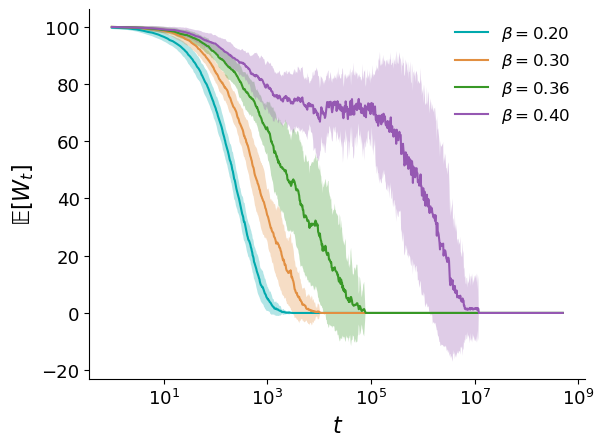

In [26]:
fig, ax = plt.subplots()

N_plotted = 100
mask = (
    (df['N'] == N_plotted) 
)
df_filtered = df[mask]

for beta in sorted(df_filtered['beta'].unique()):
    sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('time')
    plt.plot(sub_df['time'], sub_df['mean_nb_star'], label=rf'$\beta={beta:.2f}$')
    plt.fill_between(sub_df['time'],
                     sub_df['mean_nb_star'] - sub_df['std_nb_star'],
                     sub_df['mean_nb_star'] + sub_df['std_nb_star'],
                     alpha=0.3)
plt.xscale('log')
plt.xlabel(rf'$t$')
plt.ylabel(rf'$𝔼[W_t]$')
plt.legend()
plt.show()

In [ ]:
#fig.savefig(f'../results/{folder_data}/nb_star_evol_plateau_{graph_type}_{coup_type}_d{d}.pdf', bbox_inches='tight')

## Scaling below $\beta_{\rm uni}$

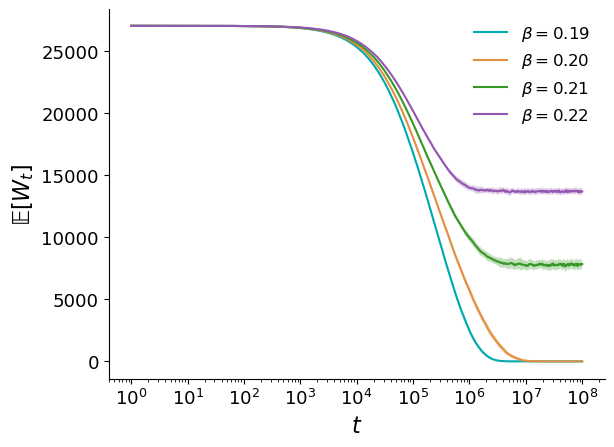

In [42]:
fig, ax = plt.subplots()

if graph_type == 'EA3D':
    N_plotted = 30
elif graph_type == 'EA2D':
    N_plotted = 300
else:
    N_plotted = 100000

mask = (
    (df['N'] == N_plotted) 
)
df_filtered = df[mask]

for beta in df_filtered['beta'].unique():
    sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('time')
    plt.plot(sub_df['time'], sub_df['mean_nb_star'], label=rf'$\beta={beta:.2f}$')
    plt.fill_between(sub_df['time'],
                     sub_df['mean_nb_star'] - sub_df['std_nb_star'],
                     sub_df['mean_nb_star'] + sub_df['std_nb_star'],
                     alpha=0.3)
plt.xscale('log')
plt.xlabel(rf'$t$')
plt.ylabel(rf'$𝔼[W_t]$')
plt.legend()
plt.show()

/tmp/ipykernel_53198/3188027686.py:44: RuntimeWarning: divide by zero encountered in log
  log_W_over_N = np.log(sub_df['mean_nb_star'].values / N)
/tmp/ipykernel_53198/3188027686.py:52: RuntimeWarning: divide by zero encountered in log
  log_W_shifted = np.log(sub_df['mean_nb_star'].values) - np.log(N)**2


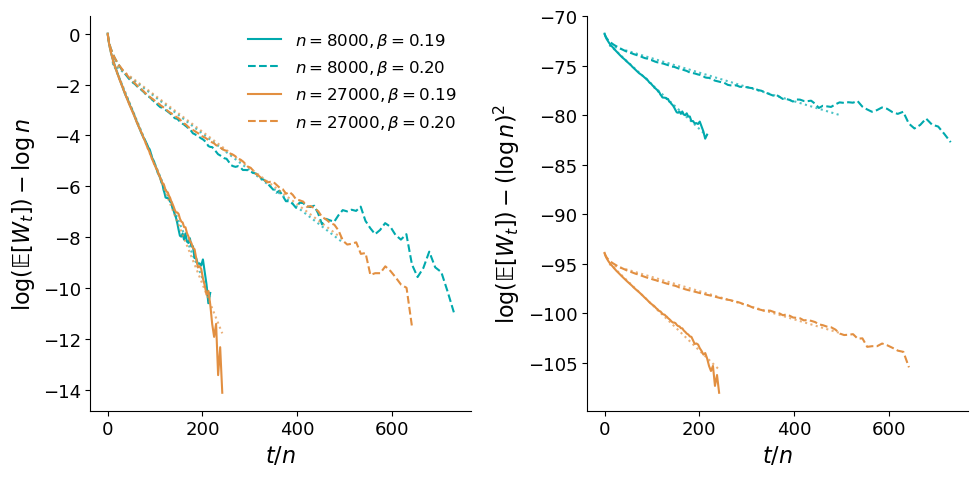

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

if graph_type == 'ER' and coup_type == 'ising':
    beta_list = [0.23, 0.24]
elif graph_type == 'ER' and coup_type == 'gauss':
    beta_list = [0.30, 0.32]
elif graph_type == 'RR' and d == 4:
    beta_list = [0.33, 0.34]
elif graph_type == 'EA2D':
    beta_list = [0.33, 0.34]
elif graph_type == 'EA3D':
    beta_list = [0.19, 0.2]
else:
    beta_list = df['beta'].unique()

if graph_type == 'EA2D':
    N_list = [100,300]
elif graph_type == 'EA3D':
    N_list = [20,30]
else:
    N_list = [10000, 100000]

t_over_min = 10
t_over_max = 500
prop_cycle = plt.rcParams['axes.prop_cycle'].by_key()['color']

for i, L in enumerate(N_list):
    color = prop_cycle[i % len(prop_cycle)]
    if graph_type == 'EA2D':
        N = L**2
    elif graph_type == 'EA3D':
        N = L**3
    else:
        N = L
    for beta in beta_list:
        csv_path = f"../results/{folder_data}/nb_star_{graph_type}_{coup_type}_d{d}_N{L}.csv"
        df = pd.read_csv(csv_path)
        sub_df = df[(df['beta'] == beta) & (df['N'] == L)].sort_values('time')
        
        t_over_N = sub_df['time'].values / N
        linestyle = '-' if beta == beta_list[0] else '--'

        # --- test 1: n ln n scaling ---
        log_W_over_N = np.log(sub_df['mean_nb_star'].values / N)
        axes[0].plot(t_over_N, log_W_over_N, color=color, linestyle=linestyle, label=rf'$n={N}, \beta={beta:.2f}$')
        mask = (t_over_N > t_over_min) & (t_over_N < t_over_max) & np.isfinite(log_W_over_N)
        if mask.sum() > 2:
            slope, intercept, r, _, _ = linregress(t_over_N[mask], log_W_over_N[mask])
            axes[0].plot(t_over_N[mask], intercept + slope * t_over_N[mask], ':', color=color, alpha=0.7)

        # --- test 2: n(ln n)^2 scaling ---
        log_W_shifted = np.log(sub_df['mean_nb_star'].values) - np.log(N)**2
        axes[1].plot(t_over_N, log_W_shifted, color=color, linestyle=linestyle, label=rf'$n={N}, \beta={beta:.2f}$')
        mask2 = (t_over_N > t_over_min) & (t_over_N < t_over_max) & np.isfinite(log_W_shifted)
        if mask2.sum() > 2:
            slope2, intercept2, r2, _, _ = linregress(t_over_N[mask2], log_W_shifted[mask2])
            axes[1].plot(t_over_N[mask2], intercept2 + slope2 * t_over_N[mask2], ':', color=color, alpha=0.7)

axes[0].set_xlabel(r'$t/n$')
axes[0].set_ylabel(r'$\log(𝔼[W_t]) - \log n$')
axes[0].legend()

axes[1].set_xlabel(r'$t/n$')
axes[1].set_ylabel(r'$\log(𝔼[W_t]) - (\log n)^2$')

plt.tight_layout()
plt.show()

/tmp/ipykernel_53198/1183683079.py:30: RuntimeWarning: divide by zero encountered in log
  log_W_over_N = np.log(sub_df['mean_nb_star'].values / N)
/tmp/ipykernel_53198/1183683079.py:37: RuntimeWarning: divide by zero encountered in log
  log_W_shifted = np.log(sub_df['mean_nb_star'].values) - np.log(N)**2


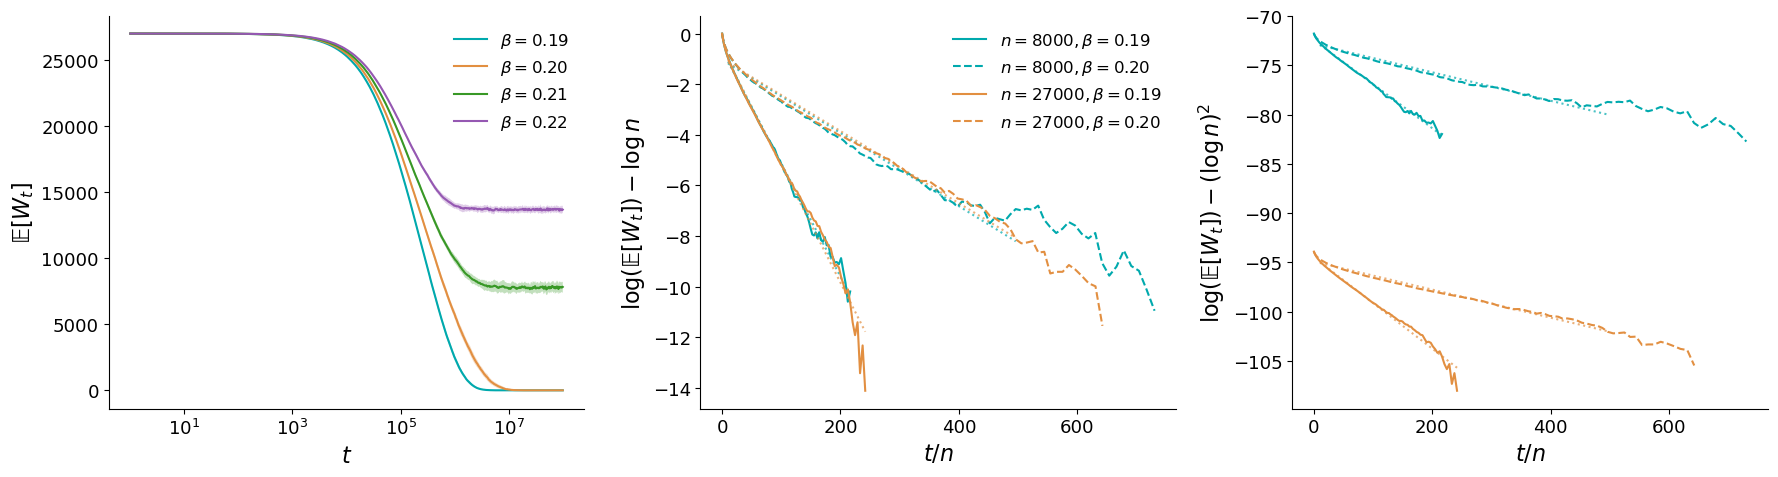

In [44]:
fig_combined, axes_c = plt.subplots(1, 3, figsize=(18, 5))

for beta in df['beta'].unique():
    sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('time')
    axes_c[0].plot(sub_df['time'], sub_df['mean_nb_star'], label=rf'$\beta={beta:.2f}$')
    axes_c[0].fill_between(sub_df['time'],
                           sub_df['mean_nb_star'] - sub_df['std_nb_star'],
                           sub_df['mean_nb_star'] + sub_df['std_nb_star'],
                           alpha=0.3)
axes_c[0].set_xscale('log')
axes_c[0].set_xlabel(r'$t$')
axes_c[0].set_ylabel(r'$𝔼[W_t]$')
axes_c[0].legend()

for i, L in enumerate(N_list):
    color = prop_cycle[i % len(prop_cycle)]
    if graph_type == 'EA2D':
        N = L**2
    elif graph_type == 'EA3D':
        N = L**3
    else:
        N = L
    for beta in beta_list:
        csv_path = f"../results/{folder_data}/nb_star_{graph_type}_{coup_type}_d{d}_N{L}.csv"
        df_N = pd.read_csv(csv_path)
        sub_df = df_N[(df_N['beta'] == beta) & (df_N['N'] == L)].sort_values('time')
        t_over_N = sub_df['time'].values / N
        linestyle = '-' if beta == beta_list[0] else '--'

        log_W_over_N = np.log(sub_df['mean_nb_star'].values / N)
        axes_c[1].plot(t_over_N, log_W_over_N, color=color, linestyle=linestyle, label=rf'$n={N}, \beta={beta:.2f}$')
        mask = (t_over_N > t_over_min) & (t_over_N < t_over_max) & np.isfinite(log_W_over_N)
        if mask.sum() > 2:
            slope, intercept, r, _, _ = linregress(t_over_N[mask], log_W_over_N[mask])
            axes_c[1].plot(t_over_N[mask], intercept + slope * t_over_N[mask], ':', color=color, alpha=0.7)

        log_W_shifted = np.log(sub_df['mean_nb_star'].values) - np.log(N)**2
        axes_c[2].plot(t_over_N, log_W_shifted, color=color, linestyle=linestyle, label=rf'$n={N}, \beta={beta:.2f}$')
        mask2 = (t_over_N > t_over_min) & (t_over_N < t_over_max) & np.isfinite(log_W_shifted)
        if mask2.sum() > 2:
            slope2, intercept2, r2, _, _ = linregress(t_over_N[mask2], log_W_shifted[mask2])
            axes_c[2].plot(t_over_N[mask2], intercept2 + slope2 * t_over_N[mask2], ':', color=color, alpha=0.7)

axes_c[1].set_xlabel(r'$t/n$')
axes_c[1].set_ylabel(r'$\log(𝔼[W_t]) - \log n$')
axes_c[1].legend()

axes_c[2].set_xlabel(r'$t/n$')
axes_c[2].set_ylabel(r'$\log(𝔼[W_t]) - (\log n)^2$')

plt.tight_layout()
#fig_combined.savefig(f'nb_star_{graph_type}_{coup_type}_d{d}.pdf', bbox_inches='tight')
plt.show()

In [45]:
fig_combined.savefig(f'../results/{folder_data}/nb_star_evol_scaling_{graph_type}_{coup_type}_d{d}.pdf', bbox_inches='tight')